In [2]:
# Importations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from datetime import timedelta, date

In [3]:
# Defining seed for reproducible outputs
np.random.seed(42)

In [4]:
# Get all 2023 dates
start_date = date(2023, 1, 1)
end_date = date(2023, 12, 31)
date_range = pd.date_range(start_date, end_date)

# Defining channels, sources and campaigns based on Dashboard

channels_sources = {
    'Programmatic': ['Amazon Ad Server', 'StackAdapt', 'Google Display & Video 360'],
    'Paid Search': ['Google Search Ads 360', 'Bing Ads (Microsoft Advertising)'],
    'Paid Social': ['LinkedIn Ads', 'Facebook'],
    'Organic': ['Organic Search', 'Direct Traffic']
}

In [5]:
channels_sources

{'Programmatic': ['Amazon Ad Server',
  'StackAdapt',
  'Google Display & Video 360'],
 'Paid Search': ['Google Search Ads 360', 'Bing Ads (Microsoft Advertising)'],
 'Paid Social': ['LinkedIn Ads', 'Facebook'],
 'Organic': ['Organic Search', 'Direct Traffic']}

In [6]:
channels_sources.items()

dict_items([('Programmatic', ['Amazon Ad Server', 'StackAdapt', 'Google Display & Video 360']), ('Paid Search', ['Google Search Ads 360', 'Bing Ads (Microsoft Advertising)']), ('Paid Social', ['LinkedIn Ads', 'Facebook']), ('Organic', ['Organic Search', 'Direct Traffic'])])

In [7]:
for i, j in channels_sources.items():
    for i in j:
        print(i)

Amazon Ad Server
StackAdapt
Google Display & Video 360
Google Search Ads 360
Bing Ads (Microsoft Advertising)
LinkedIn Ads
Facebook
Organic Search
Direct Traffic


We need to include not only the sources but the information extracted from them (impressions, clicks, etc...)

In [8]:
# A main dictionary, whose keys are the channels and its values consist of another dictionary with multiple key-value pairs for sources and dummy data
# (average, standar deviation)
channels_sources_info = {
    'Programmatic': {
        'sources': ['Amazon Ad Server', 'StackAdapt', 'Google Display & Video 360'],
        'imp': (40000, 8000), 'clicks': (500, 120), 'spend': (450, 100), 'conv': (18, 6), 'video': (8000, 2000)
        },
    'Paid Search': {
            'sources': ['Google Search Ads 360', 'Bing Ads (Microsoft Advertising)'],
            'imp': (18000, 4000), 'clicks': (1100, 250), 'spend': (1800, 400), 'conv': (65, 18), 'video': (0, 0)
        },
    'Paid Social': {
            'sources': ['LinkedIn Ads', 'Facebook'],
            'imp': (25000, 6000), 'clicks': (600, 150), 'spend': (700, 180), 'conv': (25, 8), 'video': (5000, 1500)
        },
    'Organic': {
            'sources': ['Organic Search', 'Direct Traffic'],
            'imp': (12000, 2500), 'clicks': (600, 120), 'spend': (0, 0), 'conv': (35, 10), 'video': (0, 0)
        }
}

In [9]:
# Inspecting dictionary
channels_sources_info.items()

dict_items([('Programmatic', {'sources': ['Amazon Ad Server', 'StackAdapt', 'Google Display & Video 360'], 'imp': (40000, 8000), 'clicks': (500, 120), 'spend': (450, 100), 'conv': (18, 6), 'video': (8000, 2000)}), ('Paid Search', {'sources': ['Google Search Ads 360', 'Bing Ads (Microsoft Advertising)'], 'imp': (18000, 4000), 'clicks': (1100, 250), 'spend': (1800, 400), 'conv': (65, 18), 'video': (0, 0)}), ('Paid Social', {'sources': ['LinkedIn Ads', 'Facebook'], 'imp': (25000, 6000), 'clicks': (600, 150), 'spend': (700, 180), 'conv': (25, 8), 'video': (5000, 1500)}), ('Organic', {'sources': ['Organic Search', 'Direct Traffic'], 'imp': (12000, 2500), 'clicks': (600, 120), 'spend': (0, 0), 'conv': (35, 10), 'video': (0, 0)})])

In [10]:
# Indexing the dictionary
# with info being the dictionary's value, that is, the other nested dictionary
for channel, info in channels_sources_info.items():
    print(channel)
    for key, value in info.items():
        print(f"  {key}: {value}")

Programmatic
  sources: ['Amazon Ad Server', 'StackAdapt', 'Google Display & Video 360']
  imp: (40000, 8000)
  clicks: (500, 120)
  spend: (450, 100)
  conv: (18, 6)
  video: (8000, 2000)
Paid Search
  sources: ['Google Search Ads 360', 'Bing Ads (Microsoft Advertising)']
  imp: (18000, 4000)
  clicks: (1100, 250)
  spend: (1800, 400)
  conv: (65, 18)
  video: (0, 0)
Paid Social
  sources: ['LinkedIn Ads', 'Facebook']
  imp: (25000, 6000)
  clicks: (600, 150)
  spend: (700, 180)
  conv: (25, 8)
  video: (5000, 1500)
Organic
  sources: ['Organic Search', 'Direct Traffic']
  imp: (12000, 2500)
  clicks: (600, 120)
  spend: (0, 0)
  conv: (35, 10)
  video: (0, 0)


We also need to define the campaigns. I'll assign the campaigns to different periods of the year

In [11]:
campaigns = {
    'Business-focused zero tolerance arch': (pd.Timestamp('2023-01-01'), pd.Timestamp('2023-04-30')),
    'Persistent 24/7 attitude':             (pd.Timestamp('2023-01-01'), pd.Timestamp('2023-12-31')), # Always-on
    'Integrated dedicated contingency':     (pd.Timestamp('2023-03-01'), pd.Timestamp('2023-07-31')),
    'Profound intangible policy':           (pd.Timestamp('2023-05-01'), pd.Timestamp('2023-09-30')),
    'Centralized modular throughput':       (pd.Timestamp('2023-06-01'), pd.Timestamp('2023-10-31')),
    'Automated uniform software':           (pd.Timestamp('2023-08-01'), pd.Timestamp('2023-12-31')),
    'Cross-platform static hierarchy':      (pd.Timestamp('2023-10-01'), pd.Timestamp('2023-12-31')), # Q4
    'Networked value-added time-frame':     (pd.Timestamp('2023-11-01'), pd.Timestamp('2023-12-31')),
}

In [12]:
# Selecting campaigns based on day

for d in pd.date_range('2023-01-01', '2023-12-31', freq='D'):
    active_campaigns = [
        name for name, (start, end) in campaigns.items()
        if start <= d <= end
    ]

In [13]:
# making sure it works as wanted
active_campaigns

['Persistent 24/7 attitude',
 'Automated uniform software',
 'Cross-platform static hierarchy',
 'Networked value-added time-frame']

In [14]:
rows = []
for d in pd.date_range('2023-01-01', '2023-12-31', freq='D'):
    active_campaigns = [
        name for name, (start, end) in campaigns.items()
        if start <= d <= end
    ]

    for channel, info in channels_sources_info.items():
        # Organic Traffic is not paid
        current_campaigns = ['Organic (Not Set)'] if channel == 'Organic' else active_campaigns

        for source in info['sources']:
            for campaign in current_campaigns:
                impressions = max(100, int(np.random.normal(*info['imp'])))
                # clicks can't be higher than impressions
                clicks = max(0, min(impressions, int(np.random.normal(*info['clicks']))))
                # validates non-organic traffic
                spend = round(max(0.0, np.random.normal(*info['spend'])), 2) if info['spend'][0] > 0 else 0.0
                # conversions can't be higher than the number of clicks
                conversions = max(0, min(clicks, int(np.random.normal(*info['conv']))))
                # video views can't be higher than the impressions from a specific source
                video_views = max(0, min(impressions, int(np.random.normal(*info['video'])))) if info['video'][0] > 0 else 0

                rows.append({
                    'Date': d,
                    'Channel': channel,
                    'Data Source': source,
                    'Campaign': campaign,
                    'Impressions': impressions,
                    'Clicks': clicks,
                    'Spend': spend,
                    'Conversions': conversions,
                    'Video Views': video_views
                })

df = pd.DataFrame(rows)
df

,Date,Channel,Data Source,Campaign,Impressions,Clicks,Spend,Conversions,Video Views
0,2023-01-01,Programmatic,Amazon Ad Server,Business-focused zero tolerance arch,43973,483,514.77,27,7531
1,2023-01-01,Programmatic,Amazon Ad Server,Persistent 24/7 attitude,38126,689,526.74,15,9085
2,2023-01-01,Programmatic,StackAdapt,Business-focused zero tolerance arch,36292,444,474.20,6,4550
3,2023-01-01,Programmatic,StackAdapt,Persistent 24/7 attitude,35501,378,481.42,12,5175
4,2023-01-01,Programmatic,Google Display & Video 360,Business-focused zero tolerance arch,51725,472,456.75,9,6911
...,...,...,...,...,...,...,...,...,...
9475,2023-12-31,Paid Social,Facebook,Automated uniform software,17704,550,978.70,39,5769
9476,2023-12-31,Paid Social,Facebook,Cross-platform static hierarchy,15432,418,728.81,18,5986
9477,2023-12-31,Paid Social,Facebook,Networked value-added time-frame,35055,452,538.89,15,4618
9478,2023-12-31,Organic,Organic Search,Organic (Not Set),12130,602,0.00,43,0


In [15]:
# Inspecting DataFrame
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9480 entries, 0 to 9479
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   Date         9480 non-null   datetime64[us]
 1   Channel      9480 non-null   str           
 2   Data Source  9480 non-null   str           
 3   Campaign     9480 non-null   str           
 4   Impressions  9480 non-null   int64         
 5   Clicks       9480 non-null   int64         
 6   Spend        9480 non-null   float64       
 7   Conversions  9480 non-null   int64         
 8   Video Views  9480 non-null   int64         
dtypes: datetime64[us](1), float64(1), int64(4), str(3)
memory usage: 666.7 KB


In [16]:
pd.set_option('display.max_colwidth', None)

paid_df = df[df['Channel'] != 'Organic']
print(paid_df.groupby(paid_df['Date'].dt.to_period('Q'))['Campaign'].unique())

Date
2023Q1                                                                [Business-focused zero tolerance arch, Persistent 24/7 attitude, Integrated dedicated contingency]
2023Q2    [Business-focused zero tolerance arch, Persistent 24/7 attitude, Integrated dedicated contingency, Profound intangible policy, Centralized modular throughput]
2023Q3              [Persistent 24/7 attitude, Integrated dedicated contingency, Profound intangible policy, Centralized modular throughput, Automated uniform software]
2023Q4         [Persistent 24/7 attitude, Centralized modular throughput, Automated uniform software, Cross-platform static hierarchy, Networked value-added time-frame]
Freq: Q-DEC, Name: Campaign, dtype: object


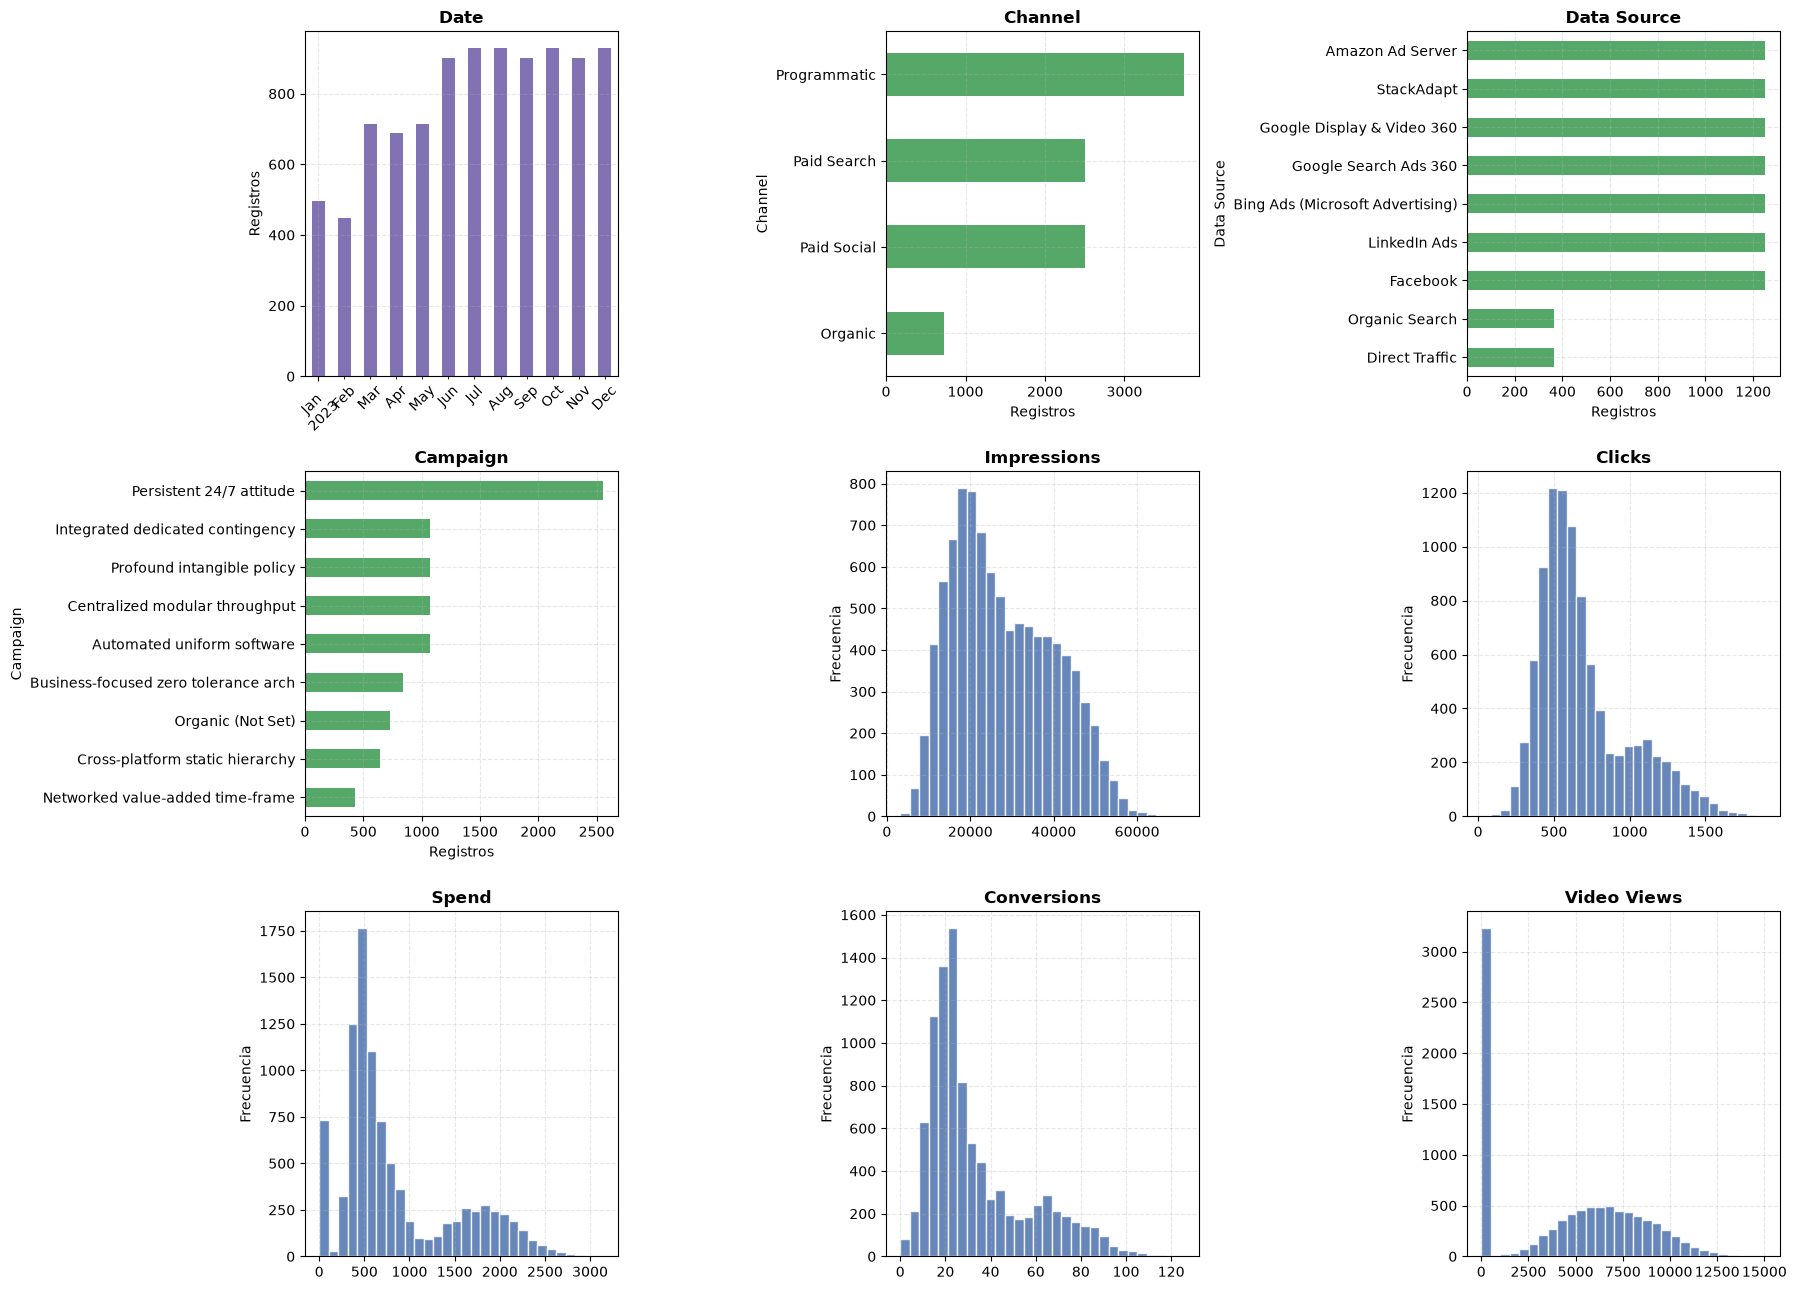

In [18]:
import matplotlib.pyplot as plt
import pandas as pd

cols = df.columns
fig, axes = plt.subplots(3, 3, figsize=(18, 13))
axes = axes.flatten()

for ax, col in zip(axes, cols):
    if pd.api.types.is_numeric_dtype(df[col]):
        ax.hist(df[col], bins=30, color='#4C72B0', edgecolor='white', alpha=0.85)
        ax.set_ylabel('Frecuencia')
    elif pd.api.types.is_datetime64_any_dtype(df[col]):
        df.groupby(df[col].dt.to_period('M')).size().plot(kind='bar', ax=ax, color='#8172B3', rot=45)
        ax.set_xlabel('')
        ax.set_ylabel('Registros')
    else:
        df[col].value_counts().plot(kind='barh', ax=ax, color='#55A868')
        ax.invert_yaxis()
        ax.set_xlabel('Registros')

    ax.set_title(col, fontweight='bold', fontsize=12)
    ax.grid(axis='both', linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

In [19]:
# 1. Conteo exacto de ceros desglosado por canal y fuente
print("=== Spend == 0 ===")
print(df[df['Spend'] == 0].groupby(['Channel', 'Data Source']).size())

print("\n=== Video Views == 0 ===")
print(df[df['Video Views'] == 0].groupby(['Channel', 'Data Source']).size())

=== Spend == 0 ===
Channel  Data Source   
Organic  Direct Traffic    365
         Organic Search    365
dtype: int64

=== Video Views == 0 ===
Channel      Data Source                     
Organic      Direct Traffic                       365
             Organic Search                       365
Paid Search  Bing Ads (Microsoft Advertising)    1250
             Google Search Ads 360               1250
Paid Social  Facebook                               1
dtype: int64
